# **1. Import Libraries**

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# **2. Load Dataset**

**Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion**

In [ ]:
from datasets import load_dataset

In [ ]:
#Load Dataset
emotion_dataset=load_dataset('dair-ai/emotion')
train_text   =emotion_dataset['train']['text']
train_label  =emotion_dataset['train']['label']


test_text    =emotion_dataset['test']['text']
test_label   =emotion_dataset['test']['label']

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)
df_test =pd.DataFrame(
    {
        'text' :test_text,
        'label' :[label_names[i] for i in test_label]
    }
)

In [ ]:
df_train.head()


,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [ ]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [ ]:
label_names=emotion_dataset['train'].features['label'].names

In [ ]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
df_train.isnull().sum()

,0
text,0
label,0


# 3. Exploratory Data Analysis (EDA)
Visualize class distribution across the 6 emotion labels. **bold text**

<Axes: xlabel='label', ylabel='count'>

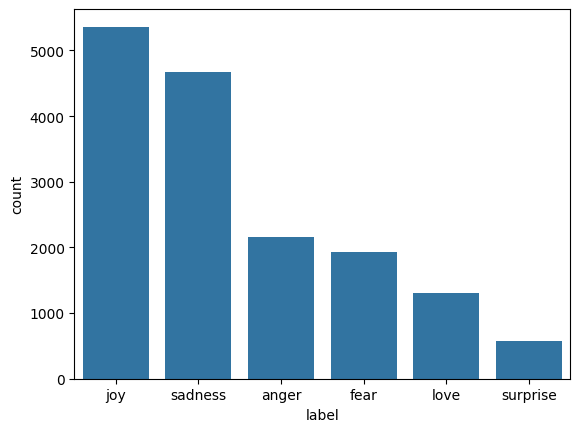

In [ ]:
sns.countplot(x='label',data=df_train, order=df_train['label'].value_counts().index)

In [ ]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

In [ ]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


# **4. Data Preprocessing - Using NLP**
Tokenize text, pad sequences to max length 50, and convert labels to NumPy arrays. **bold text**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000

tokenizer =Tokenizer(num_words=max_words ,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence =tokenizer.texts_to_sequences(df_train['text'])
test_sequence =tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence =pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence =pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

# padded_train_sequence

train_labels =np.array(train_label)
test_labels =np.array(test_label)

num_classes =len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length :{padded_train_sequence.shape[1]}")


Vocabulary Size: 15213
Max Sentence Length :50


# 5. Shared Training Utilities
Compute balanced class weights to handle dataset skew and setup early stopping. **bold text**

In [ ]:
 from sklearn.utils import class_weight

 class_weights =class_weight.compute_class_weight(
     class_weight='balanced',
     classes=np.unique(train_labels),
     y=train_labels
 )

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping =EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# **6. Phase 1 — Plain Foundational Models**
Train plain (non-bidirectional) Simple RNN, Standard LSTM, and Standard GRU models.

# 6.1 Model 1 — Simple RNN
Plain unrolled Recurrent Neural Network. **bold text**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Dense,Dropout,LSTM,GRU,Embedding

rnn_model =Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')  #Output Layer

])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
class_weight_dict = dict(enumerate(class_weights))

rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
rnn_loss,rnn_accuracy= rnn_model.evaluate(padded_test_sequence,test_labels)
print(f"rnn_loss: {rnn_loss}")
print(f"rnn_accuracy: {rnn_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.1654 - loss: 1.9219 - val_accuracy: 0.1515 - val_loss: 1.7933
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1661 - loss: 1.8030 - val_accuracy: 0.1430 - val_loss: 1.7912
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1666 - loss: 1.7780 - val_accuracy: 0.0805 - val_loss: 1.8140
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1641 - loss: 1.7649 - val_accuracy: 0.1085 - val_loss: 1.7893
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1783 - loss: 1.7266 - val_accuracy: 0.1285 - val_loss: 1.8270
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1834 - loss: 1.7058 - val_accuracy: 0.1155 - val_loss: 1.7882
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1996 - loss: 1.6779 - val_accuracy: 0.1385 - val_loss: 1.8510
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.2241 - loss: 1.6359 - val_acc

# 6.2 Model 2 — Standard LSTM
Plain stacked Long Short-Term Memory network. **bold text**

In [ ]:
lstm_model =Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')  #Output Layer

])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
lstm_loss,lstm_accuracy= lstm_model.evaluate(padded_test_sequence,test_labels)
print(f"Lstm_loss: {lstm_loss}")
print(f"Lstm_accuracy: {lstm_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.1698 - loss: 1.7947 - val_accuracy: 0.1135 - val_loss: 1.8091
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1543 - loss: 1.7939 - val_accuracy: 0.1120 - val_loss: 1.8020
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1719 - loss: 1.7935 - val_accuracy: 0.2810 - val_loss: 1.7943
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1135 - loss: 1.8091
Lstm_loss: 1.8091285228729248
Lstm_accuracy: 0.11349999904632568


# **6.3 Model 3 — Standard GRU**
Plain stacked Gated Recurrent Unit network.

In [ ]:
gru_model =Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')  #Output Layer

])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)
gru_loss,gru_accuracy= gru_model.evaluate(padded_test_sequence,test_labels)
print(f"GRU_Loss: {gru_loss}")
print(f"GRU_Accuracy: {gru_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1500 - loss: 1.7964 - val_accuracy: 0.1115 - val_loss: 1.7813
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1470 - loss: 1.7953 - val_accuracy: 0.1155 - val_loss: 1.7908
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1515 - loss: 1.7944 - val_accuracy: 0.2865 - val_loss: 1.7768
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1710 - loss: 1.7924 - val_accuracy: 0.0415 - val_loss: 1.7928
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1649 - loss: 1.7782 - val_accuracy: 0.3060 - val_loss: 1.7720
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1790 - loss: 1.7586 - val_accuracy: 0.1370 - val_loss: 1.8007
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.2089 - loss: 1.7113 - val_accuracy: 0.2355 - val_loss: 1.7758
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.2390 - loss: 1.6242 - val_accuracy: 

# **6.4 Phase 1 Ranking & Selection**
Rank foundational models to pick the best base cell for Phase 2.

In [ ]:
result_df=pd.DataFrame(
    [
        ['RNN',rnn_loss,rnn_accuracy],
        ['LSTM',lstm_loss,lstm_accuracy],
        ['GRU',gru_loss,gru_accuracy]
    ]

)
result_df

,0,1,2
0,RNN,1.788170,0.1155
1,LSTM,1.809129,0.1135
2,GRU,1.772037,0.3060


# **7. Phase 2 — Advanced Bidirectional GRU LSTM**
Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

# 7.1 Model 4 — Advanced Stacked Bidirectional GRU

In [ ]:
from tensorflow.keras.layers import Bidirectional

BiGRU =Sequential([
    Embedding(input_dim =max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #OUTPUT Layer
])
BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**Train & Evaluate Advanced Bidirectional GRU**

In [ ]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.5784 - loss: 1.0068 - val_accuracy: 0.8775 - val_loss: 0.3895
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9111 - loss: 0.2542 - val_accuracy: 0.9070 - val_loss: 0.2589
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9401 - loss: 0.1565 - val_accuracy: 0.9180 - val_loss: 0.2669
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9556 - loss: 0.1193 - val_accuracy: 0.9145 - val_loss: 0.2266
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9636 - loss: 0.0938 - val_accuracy: 0.9200 - val_loss: 0.2301
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9762 - loss: 0.0650 - val_accuracy: 0.9185 - val_loss: 0.2778
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9809 - loss: 0.0526 - val_accuracy: 0.9205 - val_loss: 0.3035


In [ ]:
BiGRU_loss,BiGRU_accuracy=BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"BiGRU_Loss: {BiGRU_loss}")
print(f"BiGRU_Accuracy: {BiGRU_accuracy}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9145 - loss: 0.2266
BiGRU_Loss: 0.22662892937660217
BiGRU_Accuracy: 0.9144999980926514


# 7.2 Model 4 — Advanced Stacked Bidirectional LSTM

In [ ]:
from tensorflow.keras.layers import Bidirectional

BiLSTM =Sequential([
    Embedding(input_dim =max_words, output_dim=300, input_length=50),
    Bidirectional(LSTM(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #OUTPUT Layer
])
BiLSTM.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BiLSTM.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**Train & Evaluate Advanced Bidirectional LSTM**

In [ ]:
BiLSTM.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.5883 - loss: 1.0351 - val_accuracy: 0.8845 - val_loss: 0.3832
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9126 - loss: 0.2672 - val_accuracy: 0.8985 - val_loss: 0.2870
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9346 - loss: 0.1943 - val_accuracy: 0.9095 - val_loss: 0.2742


In [ ]:
BiLSTM_loss,BiLSTM_accuracy=BiLSTM.evaluate(padded_test_sequence,test_labels)
print(f"BiLSTM_Loss: {BiLSTM_loss}")
print(f"BiLSTM_Accuracy: {BiLSTM_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8845 - loss: 0.3832
BiLSTM_Loss: 0.38324078917503357
BiLSTM_Accuracy: 0.8845000267028809


# **# 8. Overall Evaluation & Bias Analysis**
Consolidate test metrics, plot raw & normalized confusion matrices, and analyze bias.

8.1 Final Model Confusion Matrices (Raw Counts & Normalized %)

In [5]:
# sadness=5%,joy=14%,anger=67%,love=9%,suprise=50%,fear=2%

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


<Axes: >

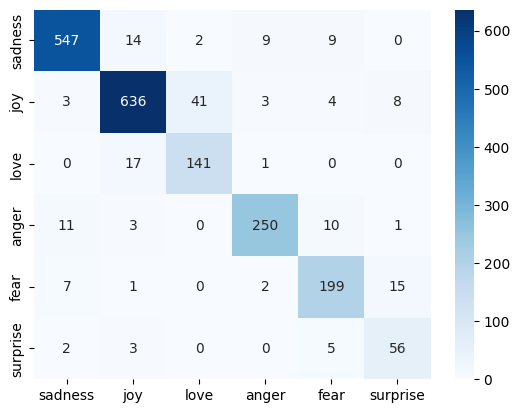

In [ ]:
from sklearn.metrics import confusion_matrix
BiGRU_predictions =np.argmax(BiGRU.predict(padded_test_sequence),axis=1)
sns.heatmap(confusion_matrix(test_labels,BiGRU_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)

# **9. Final Predictions**
Test the winning model on unseen sample sentences.

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]


sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences= pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_predictions =np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)

for i in range(len(sample_texts)):
    print(f"Text:{sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Text:I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text:I feel so alone and hopeless today.
Predicted Emotion: sadness
Text:I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text:I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text:I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


# **10. Save Model & Tokenizer**
Export trained model and tokenizer artifacts for API deployment.

In [ ]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True)

BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
    pickle.dump(tokenizer,file)